# Angles between functions: why a basis should be (nearly) orthogonal

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 4, Section "Inner Product Spaces" (the angle between two functions, Example "Monomials Are Nearly Parallel").

An inner product turns a space of functions into a geometric space: the Cauchy–Schwarz inequality lets us define
the angle $\theta$ between two non-zero functions,
$$\cos\theta = \frac{\langle u, v\rangle}{\|u\|\,\|v\|}.$$
When we approximate the solution of a variational problem by a combination of a few chosen functions, each new
function should bring a *new direction*. This notebook measures how new those directions really are, for the
most natural choice, the monomials $1, x, x^2, \dots$, and shows what goes wrong when they are not.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell (number of functions, family, inner product) and run everything again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb

# ---------------------------------------------------------------- PARAMETERS
N       = 8            # number of basis functions
family  = "monomials"  # "monomials": 1, x, ..., x^(N-1)
                       # "bubbles":   x(1-x), x^2(1-x), ...  (vanish at both ends, as in a clamped bar)
                       # "sines":     sin(pi x), sin(2 pi x), ...
product = "L2"         # "L2":     <u,v> = int u v dx
                       # "H1":     <u,v> = int (u v + u' v') dx
                       # "energy": <u,v> = int u' v' dx   (an inner product only for functions vanishing at an end)
# ---------------------------------------------------------------------------

## 1. The basis functions and the inner product

All integrals on $(0,1)$ are computed with Gauss–Legendre quadrature on 200 points: exact for polynomials up to
degree 399, and accurate to machine precision for the sines. Each family returns the values of the functions and
of their derivatives at the quadrature points.

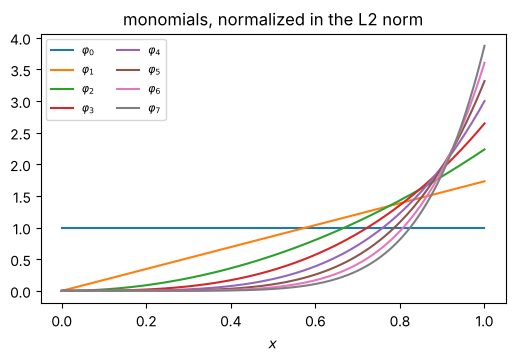

In [2]:
xg, wg = np.polynomial.legendre.leggauss(200)
xq, wq = (xg + 1) / 2, wg / 2                      # quadrature on (0,1)

def basis(family, N, x):
    """Values and derivatives of the N basis functions at the points x (arrays of shape N x len(x))."""
    n = np.arange(N)[:, None]
    if family == "monomials":
        phi  = x**n
        dphi = n * x**np.maximum(n - 1, 0)
    elif family == "bubbles":                       # x^(n+1) (1-x)
        phi  = x**(n + 1) * (1 - x)
        dphi = (n + 1) * x**n * (1 - x) - x**(n + 1)
    elif family == "sines":
        phi  = np.sin((n + 1) * np.pi * x)
        dphi = (n + 1) * np.pi * np.cos((n + 1) * np.pi * x)
    else:
        raise ValueError(family)
    return phi, dphi

def gram_matrix(phi, dphi, product):
    """G_ij = <phi_i, phi_j> computed by quadrature."""
    if product == "L2":
        return (phi * wq) @ phi.T
    if product == "H1":
        return (phi * wq) @ phi.T + (dphi * wq) @ dphi.T
    if product == "energy":
        return (dphi * wq) @ dphi.T
    raise ValueError(product)

phi, dphi = basis(family, N, xq)
G = gram_matrix(phi, dphi, product)

x = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(6, 3.5))
for k, f in enumerate(basis(family, N, x)[0]):
    ax.plot(x, f / np.sqrt(G[k, k]), label=f"$\\varphi_{{{k}}}$")
ax.set_title(f"{family}, normalized in the {product} norm")
ax.set_xlabel("$x$"); ax.legend(ncol=2, fontsize=8)
plt.show()

For monomials and the $L^2$ product the Gram matrix has a closed form,
$\langle x^i, x^j\rangle = \int_0^1 x^{i+j}\,dx = 1/(i+j+1)$: it is the **Hilbert matrix**.

In [3]:
np.set_printoptions(precision=4, suppress=True, linewidth=110)
print(G[:5, :5])

[[1.     0.5    0.3333 0.25   0.2   ]
 [0.5    0.3333 0.25   0.2    0.1667]
 [0.3333 0.25   0.2    0.1667 0.1429]
 [0.25   0.2    0.1667 0.1429 0.125 ]
 [0.2    0.1667 0.1429 0.125  0.1111]]


## 2. Angles between pairs of functions

The matrix $\cos\theta_{ij} = G_{ij}/\sqrt{G_{ii}G_{jj}}$. Values close to 1 mean nearly parallel functions.

angle between the last two functions: 4.096 degrees


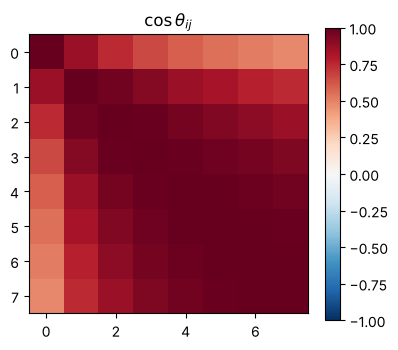

In [4]:
d = np.sqrt(np.diag(G))
C = G / np.outer(d, d)
fig, ax = plt.subplots(figsize=(4.5, 3.8))
im = ax.imshow(C, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_title(r"$\cos\theta_{ij}$"); fig.colorbar(im)
plt.show()
print("angle between the last two functions: %.3f degrees" % np.degrees(np.arccos(C[-1, -2])))

## 3. How much is new? The angle with the span of the previous functions

Pairwise angles do not tell the whole story: a new function can be far from each of its predecessors and still be
almost a combination of them. The relevant angle $\theta_n$ is the one between $\varphi_n$ and the subspace spanned
by $\varphi_0,\dots,\varphi_{n-1}$:
$$\sin\theta_n = \frac{\text{distance of } \varphi_n \text{ from that subspace}}{\|\varphi_n\|}.$$
The distance is exactly what the Gram–Schmidt procedure computes at step $n$, before normalizing. In matrix form,
Gram–Schmidt is the Cholesky factorization $G = LL^{\mathsf T}$, and the distance is the diagonal entry $L_{nn}$.

For the monomials in $L^2(0,1)$ there is a closed form, $\sin\theta_n = 1/\binom{2n}{n}$
(the part of $x^n$ orthogonal to the lower powers is the Legendre polynomial of degree $n$, divided by its
leading coefficient).

In [5]:
try:
    L = np.linalg.cholesky(G)
    sin_theta = np.diag(L) / np.sqrt(np.diag(G))
except np.linalg.LinAlgError:
    sin_theta = None
    print("Cholesky failed: in double precision the last functions are indistinguishable from")
    print("combinations of the previous ones. Reduce N.")

if sin_theta is not None:
    print(" n   theta_n [deg]" + ("   exact (monomials, L2)" if (family, product) == ("monomials", "L2") else ""))
    for n, s in enumerate(sin_theta):
        line = f"{n:2d}   {np.degrees(np.arcsin(min(s, 1))):12.6f}"
        if (family, product) == ("monomials", "L2") and n > 0:
            line += f"   {np.degrees(np.arcsin(1 / comb(2 * n, n))):12.6f}"
        print(line)

 n   theta_n [deg]   exact (monomials, L2)
 0      90.000000
 1      30.000000      30.000000
 2       9.594068       9.594068
 3       2.865984       2.865984
 4       0.818539       0.818539
 5       0.227365       0.227365
 6       0.062008       0.062008
 7       0.016695       0.016695


Each new monomial adds less than the previous one: roughly, $\theta_n$ is divided by 4 at every step.
The first entry, $90^\circ$, is a convention: $\varphi_0$ has no predecessors.

## 4. The condition number of the Gram matrix

Small angles make the Gram matrix nearly singular. Its condition number
$\kappa(G) = \lambda_{\max}/\lambda_{\min}$ is the factor by which relative errors in the data can be amplified when
we solve a linear system with $G$. In double precision, data carry about 16 significant digits: when $\kappa$
reaches $10^{16}$ nothing is left.

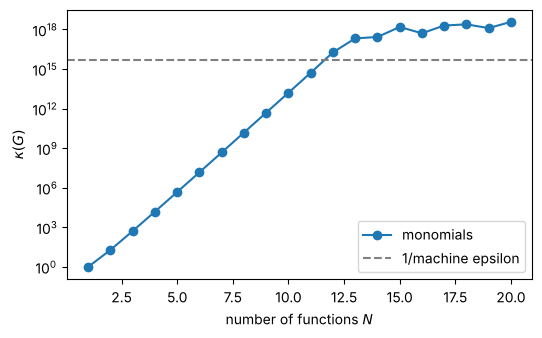

In [6]:
Ns = np.arange(1, 21)
kappa = []
for n in Ns:
    p, dp = basis(family, n, xq)
    kappa.append(np.linalg.cond(gram_matrix(p, dp, product)))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(Ns, kappa, "o-", label=family)
ax.axhline(1 / np.finfo(float).eps, color="gray", ls="--", label="1/machine epsilon")
ax.set_xlabel("number of functions $N$"); ax.set_ylabel(r"$\kappa(G)$"); ax.legend()
plt.show()

## 5. Gram–Schmidt: same space, orthonormal directions

Gram–Schmidt replaces the basis by an orthonormal one *spanning the same space*. We run it on the values at the
quadrature points (modified Gram–Schmidt, the numerically stable variant). For monomials and $L^2$ the result is
the family of shifted Legendre polynomials $\sqrt{2n+1}\,P_n(2x-1)$.

For the $H^1$ and energy products the procedure also needs the derivatives, which are transformed with the same
coefficients.

In [7]:
def inner(a, da, b, db, product):
    """<a, b> for functions given by their values (a, b) and derivatives (da, db) at the quadrature points."""
    s = 0.0
    if product in ("L2", "H1"):
        s += np.sum(wq * a * b)
    if product in ("H1", "energy"):
        s += np.sum(wq * da * db)
    return s

def gram_schmidt(phi, dphi, product):
    psi, dpsi = phi.astype(float).copy(), dphi.astype(float).copy()
    ip = lambda a, da, b, db: inner(a, da, b, db, product)
    for k in range(len(psi)):
        for j in range(k):
            c = ip(psi[k], dpsi[k], psi[j], dpsi[j])
            psi[k] -= c * psi[j]; dpsi[k] -= c * dpsi[j]
        nrm = np.sqrt(ip(psi[k], dpsi[k], psi[k], dpsi[k]))
        psi[k] /= nrm; dpsi[k] /= nrm
    return psi, dpsi

psi, dpsi = gram_schmidt(phi, dphi, product)
Gpsi = gram_matrix(psi, dpsi, product)
print("max |G - I| for the orthonormalized basis: %.1e" % np.max(np.abs(Gpsi - np.eye(N))))
print("condition number: %.3f  (it was %.2e)" % (np.linalg.cond(Gpsi), np.linalg.cond(G)))

if (family, product) == ("monomials", "L2"):
    leg = np.array([np.sqrt(2 * n + 1) * np.polynomial.legendre.Legendre.basis(n)(2 * xq - 1) for n in range(N)])
    print("max difference from the shifted Legendre polynomials: %.1e" % np.max(np.abs(np.abs(psi) - np.abs(leg))))

max |G - I| for the orthonormalized basis: 1.0e-12
condition number: 1.000  (it was 1.53e+10)
max difference from the shifted Legendre polynomials: 1.0e-11


## 6. Why it matters: the best approximation of a function

The best approximation of a function $f$ in the span of $\varphi_0,\dots,\varphi_{N-1}$ (its orthogonal projection)
is $f_N = \sum_j c_j\varphi_j$, with coefficients solving the **normal equations**
$$\sum_j \langle\varphi_i,\varphi_j\rangle\, c_j = \langle\varphi_i, f\rangle, \qquad G\,c = b.$$
With an orthonormal basis $G = I$ and $c = b$: no system to solve. Mathematically the two bases give the same $f_N$.
Numerically they do not. Here $f(x) = e^x\sin(5x)$ and the inner product is $L^2$.

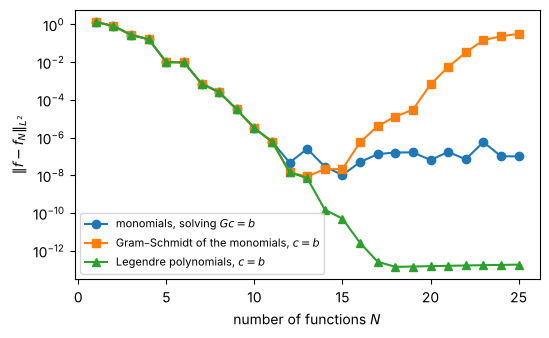

In [8]:
f = lambda x: np.exp(x) * np.sin(5 * x)

def projection_error(phi_q, use_gram_system):
    if use_gram_system:
        Gq = (phi_q * wq) @ phi_q.T
        c = np.linalg.solve(Gq, (phi_q * wq) @ f(xq))
    else:
        c = (phi_q * wq) @ f(xq)               # orthonormal basis: c_j = <phi_j, f>
    fN = c @ phi_q
    return np.sqrt(np.sum(wq * (f(xq) - fN) ** 2))

Ns = np.arange(1, 26)
err_mono, err_gs, err_leg = [], [], []
for n in Ns:
    p, dp = basis("monomials", n, xq)
    err_mono.append(projection_error(p, True))
    q, dq = gram_schmidt(p, dp, "L2")                 # Gram-Schmidt of the monomials, in floating point
    err_gs.append(projection_error(q, False))
    leg = np.array([np.sqrt(2 * k + 1) * np.polynomial.legendre.Legendre.basis(k)(2 * xq - 1) for k in range(n)])
    err_leg.append(projection_error(leg, False))     # Legendre polynomials built directly

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(Ns, err_mono, "o-", label="monomials, solving $Gc=b$")
ax.semilogy(Ns, err_gs, "s-", label="Gram–Schmidt of the monomials, $c=b$")
ax.semilogy(Ns, err_leg, "^-", label="Legendre polynomials, $c=b$")
ax.set_xlabel("number of functions $N$"); ax.set_ylabel(r"$\|f-f_N\|_{L^2}$"); ax.legend(fontsize=8)
plt.show()

The three curves coincide while $\kappa(G)$ is moderate. Beyond $N\approx 12$ the monomial error stops
decreasing: adding functions no longer improves the approximation, because the solution of $Gc=b$ is swamped by
round-off. Orthonormalizing the monomials numerically does not cure the disease, it makes it worse: Gram–Schmidt
subtracts nearly equal vectors, and the computed basis is no longer orthogonal, so $c=b$ is no longer the right
formula. The Legendre polynomials, built directly from their three-term recurrence, never pass through
the nearly parallel monomials, and the error goes down to machine precision.

The lesson: an orthogonal basis must be *constructed* well, not obtained by repairing a bad one in floating point.
(Gram–Schmidt in exact arithmetic, as Mathematica's `Orthogonalize` does on polynomials, is another way out.)

# Things to try
1. Set `family = "sines"`: the functions $\sin(n\pi x)$ are already orthogonal in $L^2$, and $\kappa(G) = 1$.
   Are they still orthogonal for `product = "H1"`? And for `product = "energy"`?
2. Set `family = "bubbles"` and `product = "energy"`: the basis of a clamped bar used in the chapter on numerical
   approximation. How fast does $\kappa(G)$ grow?
3. Change $f$ in Section 6 to a function with a kink, e.g. `np.abs(x - 1/3)`. How fast does the error decrease now?